### Análise Exploratória dos Dados 

In [ ]:
from pathlib import Path
import pandas as pd

base_path = Path.cwd().parent  
file_path = base_path / "data" / "raw" / "Base_de_Dados_IDSC-BR_2025.xlsx"

df = pd.read_excel(file_path, sheet_name="Todos os Dados")

df.head()

,ID,Município,População_2022,UF,Pontuação Indice ODS 2025,Classificação 2025,Valores faltantes,Porcentagem valores faltantes,Goal 1 Score,Goal 2 Score,...,Normalizado (0-100): SDG16_TRANSP,Painel: SDG16_TRANSP,SDG17_1_INVST_PB,year_SDG17_1_INVST_PB,Normalizado (0-100): SDG17_1_INVST_PB,Painel: SDG17_1_INVST_PB,SDG17_3_P_RC_TRB,year_SDG17_3_P_RC_TRB,Normalizado (0-100): SDG17_3_P_RC_TRB,Painel: SDG17_3_P_RC_TRB
0,1100015,Alta Floresta D'Oeste,21495,RO,41.885064,5182,4,4.0,53.769451,53.255278,...,66.667,yellow,13.216,2023.0,0.000000,red,5.257,2023.0,8.108054,orange
1,1100023,Ariquemes,96833,RO,45.475390,4448,1,1.0,54.219225,50.890756,...,66.667,yellow,85.642,2023.0,1.133196,red,18.394,2023.0,34.298246,yellow
2,1100031,Cabixi,5363,RO,47.569518,3758,6,6.0,49.228293,43.817398,...,66.667,yellow,909.852,2023.0,38.715329,green,5.686,2023.0,8.963317,orange
3,1100049,Cacoal,86895,RO,48.582323,3366,0,0.0,50.752090,51.083977,...,50.000,yellow,328.073,2023.0,12.187507,orange,21.627,2023.0,40.743620,green
4,1100056,Cerejeiras,15890,RO,48.718897,3312,2,2.0,56.552994,50.268036,...,66.667,yellow,246.352,2023.0,8.461212,orange,12.178,2023.0,21.905901,yellow


In [4]:
df.shape

(5570, 442)

In [5]:
df.describe()

,ID,População_2022,Pontuação Indice ODS 2025,Classificação 2025,Valores faltantes,Porcentagem valores faltantes,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 4 Score,...,Normalizado (0-100): SDG16_DRTHMN,SDG16_TRANSP,year_SDG16_TRANSP,Normalizado (0-100): SDG16_TRANSP,SDG17_1_INVST_PB,year_SDG17_1_INVST_PB,Normalizado (0-100): SDG17_1_INVST_PB,SDG17_3_P_RC_TRB,year_SDG17_3_P_RC_TRB,Normalizado (0-100): SDG17_3_P_RC_TRB
count,5.570000e+03,5.570000e+03,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,5570.000000,...,5570.000000,5570.000000,5570.0,5570.000000,5567.000000,5567.000000,5567.000000,5567.000000,5567.000000,5567.000000
mean,3.253591e+06,3.645647e+04,49.990494,2785.500000,3.068402,3.068417,47.571009,46.624911,71.170731,56.284416,...,43.541804,57.396914,2019.0,57.396914,620.901530,2022.987067,24.299321,8.177923,2022.986348,13.921535
std,9.849103e+05,2.065170e+05,5.438557,1608.064831,1.747221,1.747214,8.695030,7.933840,7.900917,10.689403,...,12.573907,9.624135,0.0,9.624135,673.616023,0.151094,22.258575,6.686952,0.152216,13.175086
min,1.100015e+06,8.330000e+02,28.417958,1.000000,0.000000,0.000000,14.814576,8.754316,32.299674,14.981179,...,0.000000,0.000000,2019.0,0.000000,0.077000,2019.000000,0.000000,0.043000,2018.000000,0.000000
25%,2.512126e+06,5.228000e+03,46.413710,1393.250000,2.000000,2.000000,42.280097,41.712795,65.913527,49.221609,...,28.571000,50.000000,2019.0,50.000000,256.148000,2023.000000,8.907888,3.686500,2023.000000,4.977073
50%,3.146280e+06,1.106500e+04,50.057603,2785.500000,3.000000,3.000000,48.077334,46.888490,71.284242,57.690439,...,42.857000,50.000000,2019.0,50.000000,445.867000,2023.000000,17.558650,6.003000,2023.000000,9.595295
75%,4.119190e+06,2.442725e+04,53.658757,4177.750000,4.000000,4.000000,53.216039,51.779660,76.514048,63.926508,...,57.143000,66.667000,2019.0,66.667000,760.505000,2023.000000,31.905439,10.542000,2023.000000,18.644338
max,5.300108e+06,1.145124e+07,66.834441,5570.000000,16.000000,16.000000,79.930355,74.836187,96.341519,91.219539,...,100.000000,83.333000,2019.0,83.333000,16190.321000,2023.000000,100.000000,93.303000,2023.000000,100.000000


In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

features_interesse = [
    'SDG4_16_IDEB_AI',      # Alvo: IDEB Anos Iniciais
    'SDG6_7_ESG_SAN',       # Saneamento
    'SDG1_4_R_1_4_SM',      # Renda Baixa (até 1/4 SM)
    'SDG10_22_ADER',        # Desigualdade Racial (Distorção Idade-Série)
    'SDG3_27_DSP_SAU',      # Gasto Saúde per capita
    'SDG4_1_P_EF_INT',      # Internet nas Escolas
    'SDG13_2_CO2'           # Emissões (Contexto ambiental/industrial)
]

# estética 
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [7]:
df_analysis = df[features_interesse].apply(pd.to_numeric, errors='coerce')
df_analysis = df_analysis.dropna() 

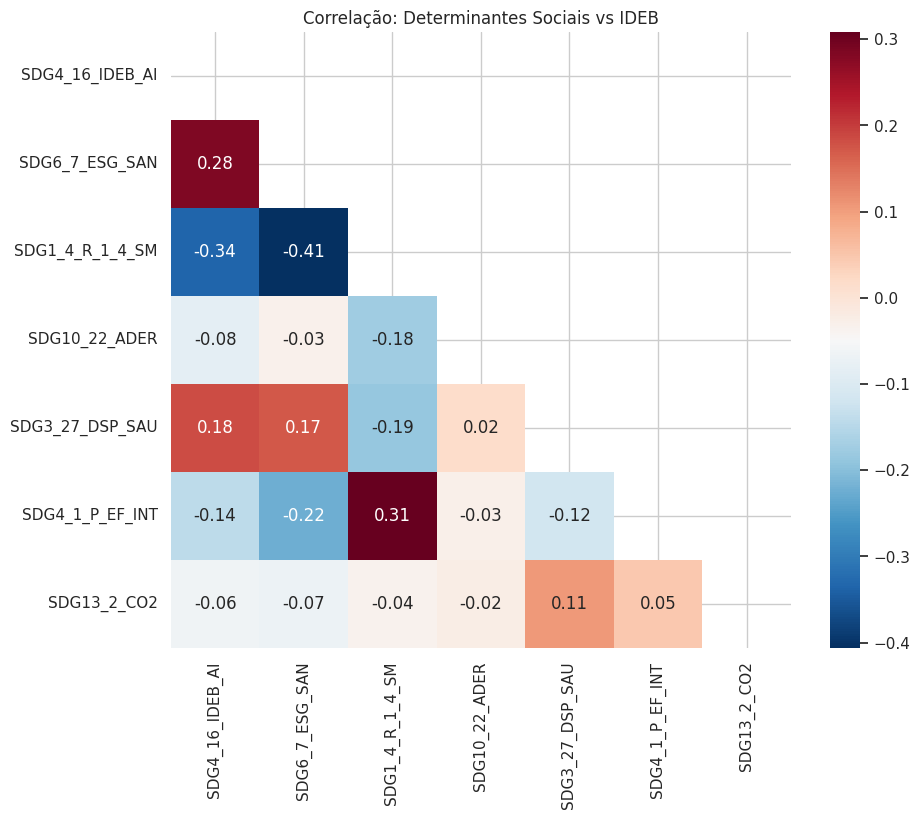

In [8]:
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(df_analysis .corr(), dtype=bool))
sns.heatmap(df_analysis .corr(), annot=True, cmap='RdBu_r', mask=mask, fmt=".2f")
plt.title('Correlação: Determinantes Sociais vs IDEB')
plt.show()

- A correlação entre IDEB (SDG4_16) e Baixa Renda (SDG1_4) é de -0.34. É a correlação negativa mais forte da sua matriz. Economia como preditor da base.
 
- A correlação de 0.28 entre Esgotamento Sanitário (SDG6_7) e IDEB indica que infraestrutura física tem um impacto positivo direto. 

- A correlação entre Internet nas Escolas (SDG4_1) e IDEB deu negativa (-0.14).

- Provavelmente, em cidades ricas a internet tem um efeito, e em cidades pobres, outro. O modelo global se "confunde" e gera esse valor negativo. Internet pode ser uma política de assistência. 

- A relação entre Esgoto (SDG6_7) e Baixa Renda (SDG1_4): -0.41.


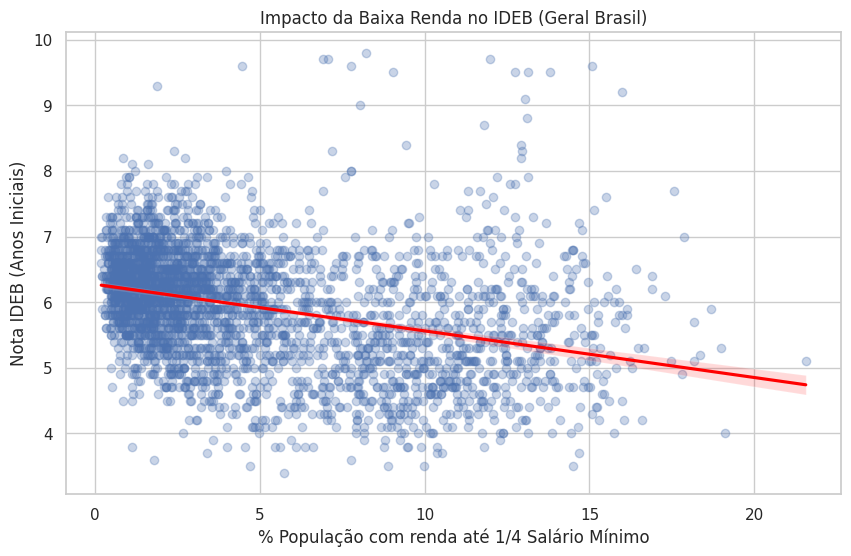

In [9]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_analysis, x='SDG1_4_R_1_4_SM', y='SDG4_16_IDEB_AI', 
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title('Impacto da Baixa Renda no IDEB (Geral Brasil)')
plt.xlabel('% População com renda até 1/4 Salário Mínimo')
plt.ylabel('Nota IDEB (Anos Iniciais)')
plt.show()

 - Baixa Pobreza (Lado Esquerdo):Dispersão maior. Quando possui renda estável outros fatores (gestão, saneamento, internet), influenciam mais no resultados. 

 - Alta Pobreza (Lado Direito): A nuvem de pontos desce e se concentra. 

 - A linha vermelha tenta resumir o Brasil inteiro, porém possui cidades que estão nos extremos superiores (os outliers positivos).


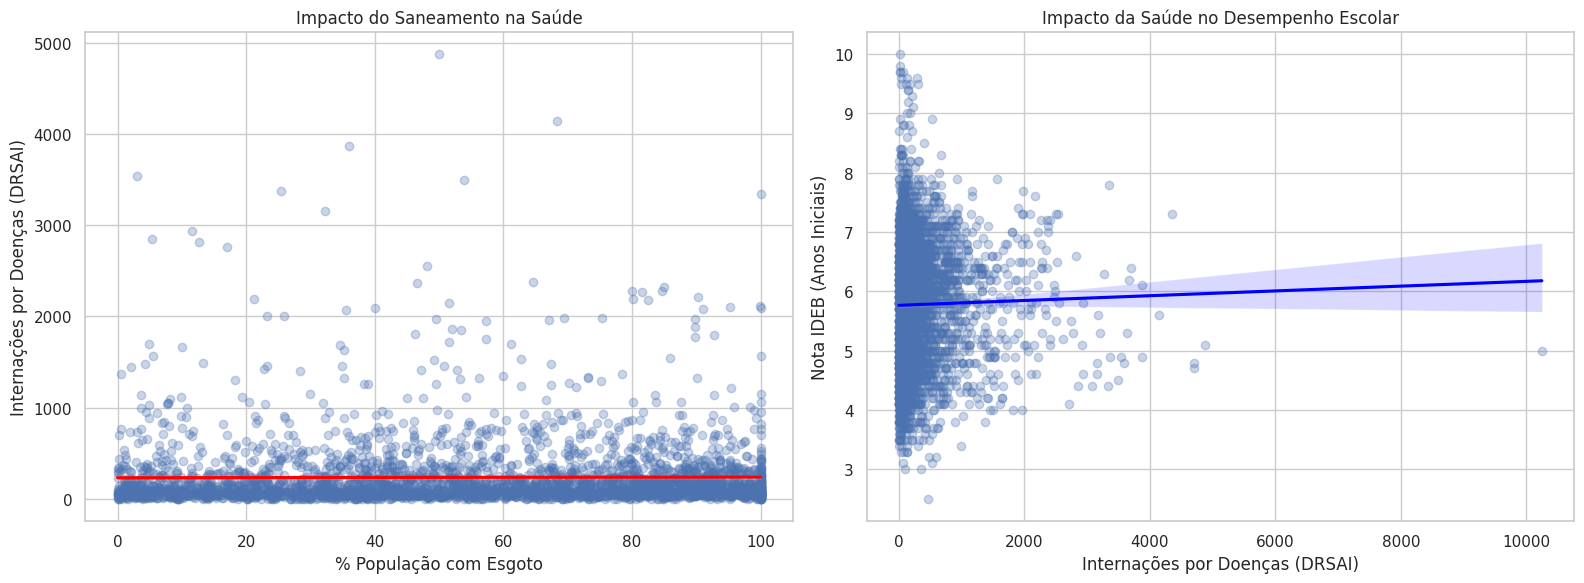

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.regplot(data=df, x='SDG6_7_ESG_SAN', y='SDG6_1_IN_DRSAI', ax=ax1, 
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
ax1.set_title('Impacto do Saneamento na Saúde')
ax1.set_xlabel('% População com Esgoto')
ax1.set_ylabel('Internações por Doenças (DRSAI)')

sns.regplot(data=df, x='SDG6_1_IN_DRSAI', y='SDG4_16_IDEB_AI', ax=ax2, 
            scatter_kws={'alpha':0.3}, line_kws={'color':'blue'})
ax2.set_title('Impacto da Saúde no Desempenho Escolar')
ax2.set_xlabel('Internações por Doenças (DRSAI)')
ax2.set_ylabel('Nota IDEB (Anos Iniciais)')
plt.tight_layout()
plt.show()

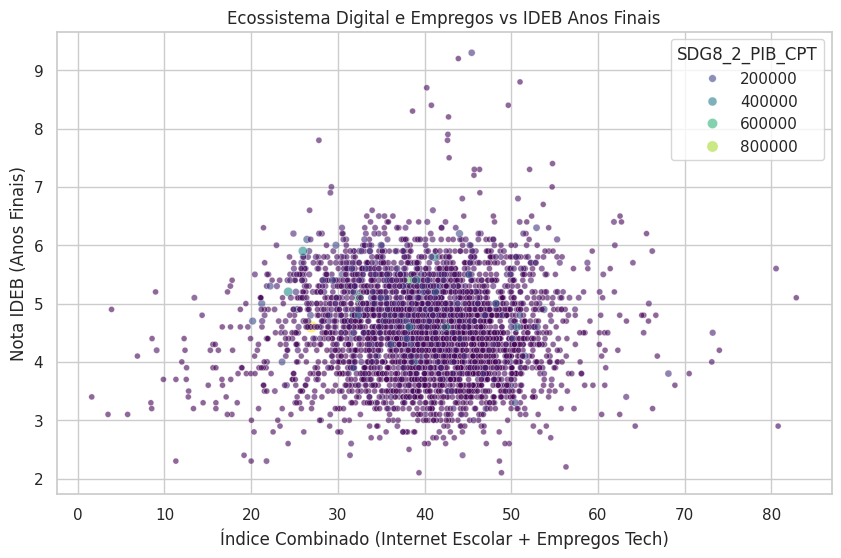

In [11]:

plt.figure(figsize=(10, 6))

# Criação de uma métrica combinada de "Ecossistema Digital" para visualizar
df['ECOSSISTEMA_DIGITAL'] = (df['SDG4_1_P_EF_INT'] + df['SDG9_2_EMP_INT']) / 2
sns.scatterplot(data=df, x='ECOSSISTEMA_DIGITAL', y='SDG4_15_IDEB_AF', 
                size='SDG8_2_PIB_CPT', hue='SDG8_2_PIB_CPT', palette='viridis', alpha=0.6)
plt.title('Ecossistema Digital e Empregos vs IDEB Anos Finais')
plt.xlabel('Índice Combinado (Internet Escolar + Empregos Tech)')
plt.ylabel('Nota IDEB (Anos Finais)')
plt.show()

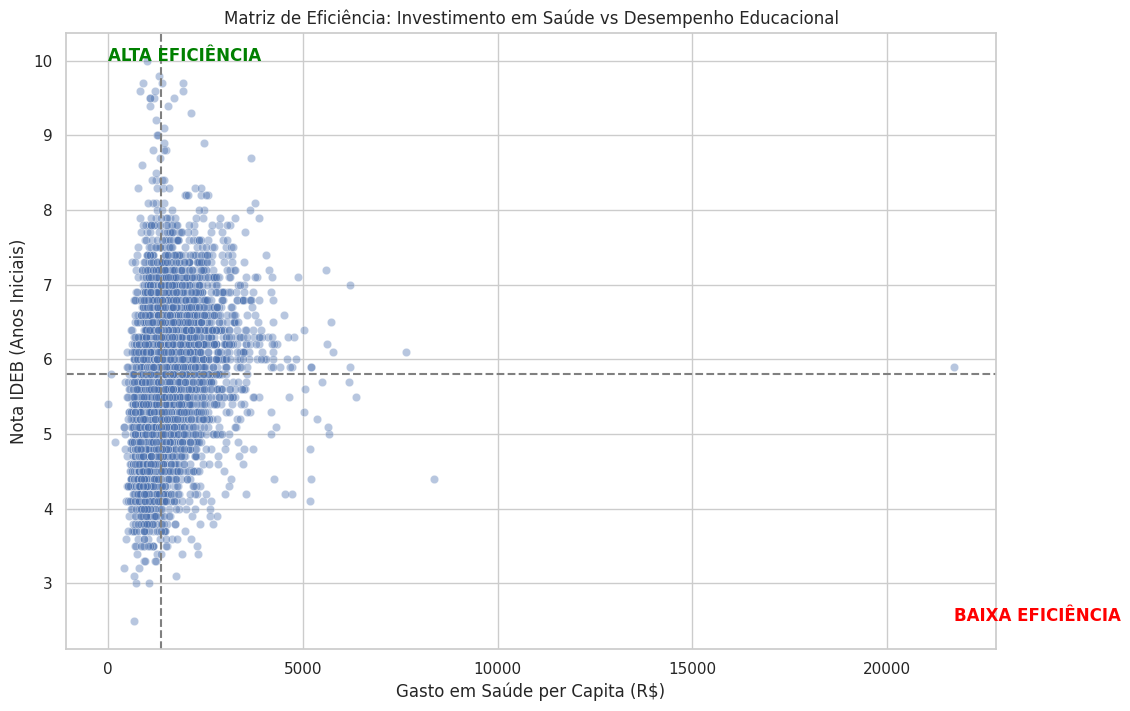

In [12]:

plt.figure(figsize=(12, 8))
med_invest = df['SDG3_27_DSP_SAU'].median()
med_ideb = df['SDG4_16_IDEB_AI'].median()

sns.scatterplot(data=df, x='SDG3_27_DSP_SAU', y='SDG4_16_IDEB_AI', alpha=0.4)

plt.axvline(med_invest, color='gray', linestyle='--')
plt.axhline(med_ideb, color='gray', linestyle='--')

plt.text(df['SDG3_27_DSP_SAU'].min(), df['SDG4_16_IDEB_AI'].max(), 'ALTA EFICIÊNCIA', fontsize=12, color='green', fontweight='bold')
plt.text(df['SDG3_27_DSP_SAU'].max(), df['SDG4_16_IDEB_AI'].min(), 'BAIXA EFICIÊNCIA', fontsize=12, color='red', fontweight='bold')

plt.title('Matriz de Eficiência: Investimento em Saúde vs Desempenho Educacional')
plt.xlabel('Gasto em Saúde per Capita (R$)')
plt.ylabel('Nota IDEB (Anos Iniciais)')
plt.show()

Possíveis Indicadores para Clustering

SDG1_4_R_1_4_SM (Pobreza): Para separar o eixo X do seu gráfico.

SDG8_2_PIB_CPT (PIB per capita): Para diferenciar cidades industriais/ricas de cidades de serviço.

SDG6_7_ESG_SAN (Saneamento): Um ótimo proxy para maturidade de infraestrutura urbana.

SDG17_1_INVST_PB (Investimento): Para separar cidades com alta vs. baixa capacidade de caixa.

SDG13_2_CO2 (Emissões): Funciona muito bem para identificar se o perfil da cidade é Agrícola/Preservação ou Industrial/Urbano.


